# ImmoAnalyse — Exploration des résultats du pipeline

Ce notebook lit les fichiers produits par `python -m src.main` :
données propres, quarantaine et rapport de qualité.

**Avant de l'exécuter**, lance le pipeline depuis la racine du projet :
`python -m src.main`.

Les données sont synthétiques : elles ne servent pas à estimer le marché réel.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RACINE = Path("..")
propres = pd.read_csv(RACINE / "data" / "processed" / "donnees_propres.csv")
quarantaine = pd.read_csv(RACINE / "data" / "quarantine" / "quarantaine.csv")
doublons = pd.read_csv(RACINE / "data" / "quarantine" / "doublons_ecartes.csv")
regles = pd.read_csv(RACINE / "reports" / "quality_summary.csv")
with open(RACINE / "reports" / "quality_report.json", encoding="utf-8") as f:
    indicateurs = json.load(f)

print(len(propres), "retenues |", len(quarantaine), "en quarantaine |",
      len(doublons), "doublons écartés")

2924 retenues | 246 en quarantaine | 14 doublons écartés


## 1. Du brut aux données retenues

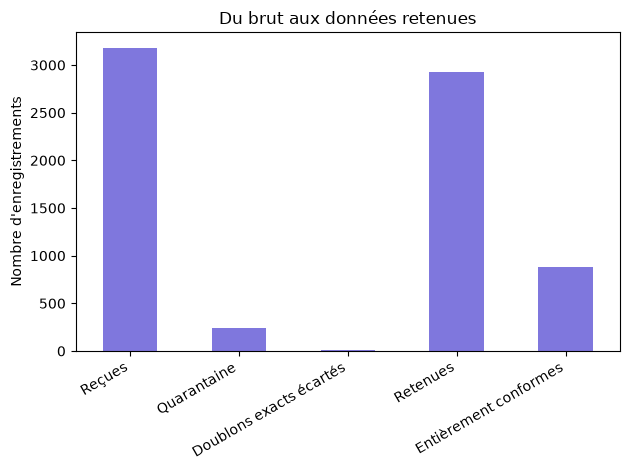

Taux global de conformité : 27.8 %


In [2]:
entonnoir = pd.Series({
    "Reçues": indicateurs["total_recus"],
    "Quarantaine": indicateurs["enregistrements_en_quarantaine"],
    "Doublons exacts écartés": indicateurs["enregistrements_ecartes_doublons"],
    "Retenues": indicateurs["enregistrements_retenus"],
    "Entièrement conformes": indicateurs["entierement_conformes"],
})
entonnoir.plot(kind="bar", color="#7F77DD")
plt.title("Du brut aux données retenues")
plt.ylabel("Nombre d'enregistrements")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
print(f"Taux global de conformité : {indicateurs['taux_global_conformite_pct']} %")

## 2. Qualité par source

In [3]:
recues = pd.Series(indicateurs["recus_par_source"])
en_quarantaine = quarantaine["source"].value_counts()
par_source = pd.DataFrame({"recues": recues, "quarantaine": en_quarantaine}).fillna(0)
par_source["taux_quarantaine_pct"] = (par_source["quarantaine"] / par_source["recues"] * 100).round(1)
par_source.sort_values("taux_quarantaine_pct", ascending=False)

,recues,quarantaine,taux_quarantaine_pct
particuliers,731,136,18.6
agence,640,68,10.6
notaires,410,20,4.9
historique,528,10,1.9
plateforme,875,12,1.4


## 2 bis. Profilage détaillé de chaque source

In [4]:
from IPython.display import Markdown
Markdown((RACINE / "reports" / "profilage_par_source.md").read_text(encoding="utf-8"))

# Profilage par source

Pour chaque source : volume, colonnes présentes, valeurs manquantes, doublons exacts, erreurs de conversion et distributions.

## Source : agence

- Lignes : **640**
- Colonnes absentes de cette source : type_transaction, quartier, devise, pieces
- Doublons exacts (colonnes brutes) : 0
- Erreurs de conversion : {'prix': 0, 'surface': 0, 'date': 0}

**Valeurs manquantes (colonnes présentes)**

|             |   manquants |   taux_pct |
|:------------|------------:|-----------:|
| id_local    |           0 |          0 |
| date        |           0 |          0 |
| type_bien   |           0 |          0 |
| region      |           0 |          0 |
| ville       |           0 |          0 |
| prix        |           0 |          0 |
| surface     |           0 |          0 |
| chambres    |           0 |          0 |
| salles_bain |           0 |          0 |
| statut      |           0 |          0 |

**Distribution du prix et de la surface (après conversion)**

|         |   prix_nombre |   surface_nombre |
|:--------|--------------:|-----------------:|
| nombre  | 640           |            640   |
| moyenne |   9.0903e+07  |            238   |
| minimum |   0           |            -30   |
| mediane |   6.4513e+07  |            154.8 |
| maximum |   5.36187e+08 |           1489.5 |

**Types de bien**

| type_bien_ref    |   count |
|:-----------------|--------:|
| Appartement      |     179 |
| Maison           |     149 |
| Villa            |     123 |
| Terrain          |      96 |
| Studio           |      67 |
| Chambre          |      17 |
| Local commercial |       9 |

**Villes principales**

| ville_ref   |   count |
|:------------|--------:|
| Koungheul   |      28 |
| Ourossogui  |      25 |
| Bounkiling  |      21 |
| Ziguinchor  |      20 |
| Guinguinéo  |      20 |

## Source : historique

- Lignes : **528**
- Colonnes absentes de cette source : type_transaction, quartier, devise, pieces, statut
- Doublons exacts (colonnes brutes) : 0
- Erreurs de conversion : {'prix': 0, 'surface': 0, 'date': 0}

**Valeurs manquantes (colonnes présentes)**

|             |   manquants |   taux_pct |
|:------------|------------:|-----------:|
| id_local    |           0 |        0   |
| date        |           0 |        0   |
| type_bien   |           0 |        0   |
| region      |           0 |        0   |
| ville       |           8 |        1.5 |
| prix        |          10 |        1.9 |
| surface     |           0 |        0   |
| chambres    |           0 |        0   |
| salles_bain |           0 |        0   |

**Distribution du prix et de la surface (après conversion)**

|         |   prix_nombre |   surface_nombre |
|:--------|--------------:|-----------------:|
| nombre  | 518           |            528   |
| moyenne |   9.27096e+07 |            223.6 |
| minimum |   5.492e+06   |             10.2 |
| mediane |   6.764e+07   |            135.2 |
| maximum |   4.40285e+08 |           1448.8 |

**Types de bien**

| type_bien_ref    |   count |
|:-----------------|--------:|
| Local commercial |      88 |
| Maison           |      82 |
| Appartement      |      79 |
| Chambre          |      73 |
| Terrain          |      71 |
| Villa            |      71 |
| Studio           |      64 |

**Villes principales**

| ville_ref   |   count |
|:------------|--------:|
| Vélingara   |      20 |
| Ourossogui  |      19 |
| Linguère    |      18 |
| Ziguinchor  |      17 |
| Goudomp     |      17 |

## Source : notaires

- Lignes : **410**
- Colonnes absentes de cette source : type_transaction, quartier, devise, pieces, salles_bain
- Doublons exacts (colonnes brutes) : 0
- Erreurs de conversion : {'prix': 0, 'surface': 0, 'date': 6}

**Valeurs manquantes (colonnes présentes)**

|           |   manquants |   taux_pct |
|:----------|------------:|-----------:|
| id_local  |           0 |        0   |
| date      |           0 |        0   |
| type_bien |           0 |        0   |
| region    |           0 |        0   |
| ville     |           0 |        0   |
| prix      |          14 |        3.4 |
| surface   |           0 |        0   |
| chambres  |           0 |        0   |
| statut    |           0 |        0   |

**Distribution du prix et de la surface (après conversion)**

|         |   prix_nombre |   surface_nombre |
|:--------|--------------:|-----------------:|
| nombre  | 396           |            410   |
| moyenne |   1.23726e+08 |            234.9 |
| minimum |   5.446e+06   |             12.7 |
| mediane |   8.16355e+07 |            154.2 |
| maximum |   5.67559e+08 |           1498   |

**Types de bien**

| type_bien_ref    |   count |
|:-----------------|--------:|
| Maison           |     106 |
| Villa            |      98 |
| Appartement      |      92 |
| Studio           |      51 |
| Terrain          |      43 |
| Chambre          |      15 |
| Local commercial |       5 |

**Villes principales**

| ville_ref   |   count |
|:------------|--------:|
| Kanel       |      16 |
| Gossas      |      15 |
| Kébémer     |      15 |
| Pikine      |      14 |
| Bounkiling  |      13 |

## Source : particuliers

- Lignes : **731**
- Colonnes absentes de cette source : quartier, devise, pieces
- Doublons exacts (colonnes brutes) : 0
- Erreurs de conversion : {'prix': 2, 'surface': 4, 'date': 0}

**Valeurs manquantes (colonnes présentes)**

|                  |   manquants |   taux_pct |
|:-----------------|------------:|-----------:|
| id_local         |           0 |        0   |
| date             |           0 |        0   |
| type_transaction |           0 |        0   |
| type_bien        |           0 |        0   |
| region           |           0 |        0   |
| ville            |           0 |        0   |
| prix             |          61 |        8.3 |
| surface          |          75 |       10.3 |
| chambres         |           0 |        0   |
| salles_bain      |           0 |        0   |
| statut           |           0 |        0   |

**Distribution du prix et de la surface (après conversion)**

|         |     prix_nombre |   surface_nombre |
|:--------|----------------:|-----------------:|
| nombre  |   668           |            652   |
| moyenne |     6.63204e+07 |            259.6 |
| minimum | 45000           |             10.6 |
| mediane |     4.30105e+07 |            147.4 |
| maximum |     5.10157e+08 |           1484.6 |

**Types de bien**

| type_bien_ref    |   count |
|:-----------------|--------:|
| Appartement      |     176 |
| Maison           |     153 |
| Terrain          |     142 |
| Villa            |     101 |
| Studio           |      94 |
| Chambre          |      43 |
| Local commercial |      22 |

**Villes principales**

| ville_ref   |   count |
|:------------|--------:|
| Kébémer     |      26 |
| Dakar       |      25 |
| Bignona     |      25 |
| Matam       |      23 |
| Koungheul   |      23 |

## Source : plateforme

- Lignes : **875**
- Colonnes absentes de cette source : chambres
- Doublons exacts (colonnes brutes) : 15
- Erreurs de conversion : {'prix': 6, 'surface': 0, 'date': 0}

**Valeurs manquantes (colonnes présentes)**

|                  |   manquants |   taux_pct |
|:-----------------|------------:|-----------:|
| id_local         |           0 |        0   |
| date             |           0 |        0   |
| type_transaction |           0 |        0   |
| type_bien        |           0 |        0   |
| region           |           0 |        0   |
| ville            |           0 |        0   |
| quartier         |           0 |        0   |
| prix             |           0 |        0   |
| devise           |           0 |        0   |
| surface          |           5 |        0.6 |
| pieces           |           0 |        0   |
| salles_bain      |           0 |        0   |
| statut           |           0 |        0   |

**Distribution du prix et de la surface (après conversion)**

|         |     prix_nombre |   surface_nombre |
|:--------|----------------:|-----------------:|
| nombre  |   869           |            870   |
| moyenne |     8.4478e+07  |            241   |
| minimum | 40000           |             10.2 |
| mediane |     5.7208e+07  |            145.8 |
| maximum |     5.51163e+08 |           1494.8 |

**Types de bien**

| type_bien_ref    |   count |
|:-----------------|--------:|
| Appartement      |     225 |
| Maison           |     188 |
| Villa            |     151 |
| Terrain          |     123 |
| Studio           |     107 |
| Chambre          |      41 |
| Local commercial |      40 |

**Villes principales**

| ville_ref          |   count |
|:-------------------|--------:|
| Kaffrine           |      29 |
| Médina Yoro Foulah |      29 |
| Goudomp            |      29 |
| Kébémer            |      27 |
| Goudiry            |      27 |


## 3. Pourquoi des lignes sont en quarantaine

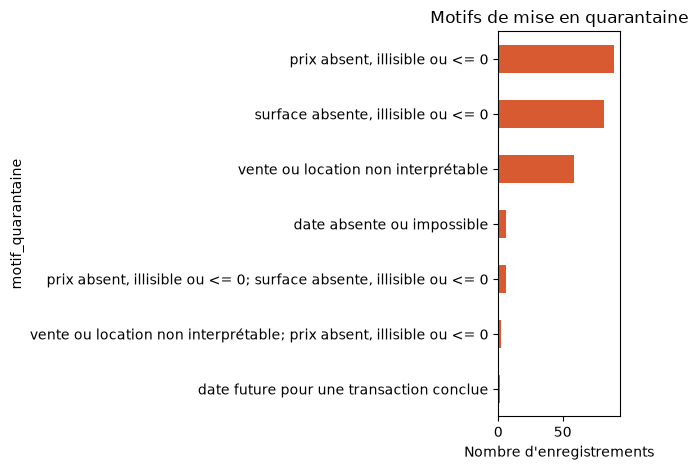

In [5]:
motifs = quarantaine["motif_quarantaine"].value_counts()
motifs.sort_values().plot(kind="barh", color="#D85A30")
plt.title("Motifs de mise en quarantaine")
plt.xlabel("Nombre d'enregistrements")
plt.tight_layout()
plt.show()

## 4. Conformité par règle

Taux = conformes / évaluables × 100. Les valeurs **non évaluables** sont comptées
à part : on ne les considère pas comme conformes.

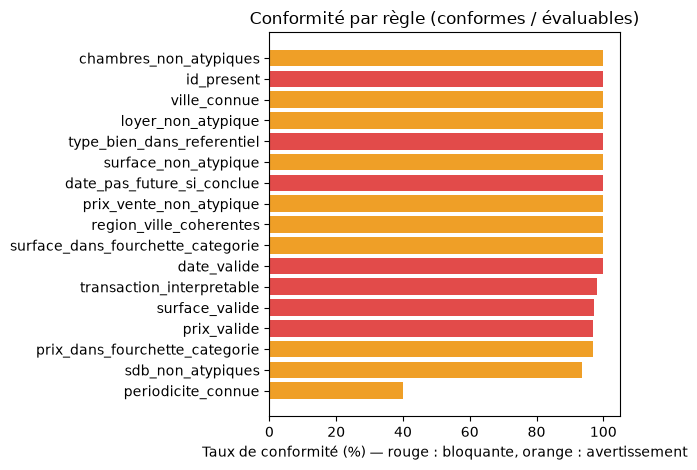

,regle,conformes,non_conformes,non_evaluables
0,id_present,3184,0,0
1,transaction_interpretable,3123,61,0
2,prix_valide,3086,98,0
3,surface_valide,3096,88,0
4,date_valide,3178,6,0
5,date_pas_future_si_conclue,1848,1,1335
6,type_bien_dans_referentiel,3184,0,0
7,surface_non_atypique,3096,4,84
8,prix_vente_non_atypique,2608,3,573
9,loyer_non_atypique,177,0,3007


In [6]:
tableau = regles.dropna(subset=["taux_conformite_pct"]).sort_values("taux_conformite_pct")
couleurs = ["#E24B4A" if g == "bloquante" else "#EF9F27" for g in tableau["gravite"]]
plt.barh(tableau["regle"], tableau["taux_conformite_pct"], color=couleurs)
plt.xlabel("Taux de conformité (%) — rouge : bloquante, orange : avertissement")
plt.title("Conformité par règle (conformes / évaluables)")
plt.tight_layout()
plt.show()
regles[["regle", "conformes", "non_conformes", "non_evaluables"]]

## 5. Avertissements les plus fréquents (lignes conservées)

In [7]:
(propres["avertissements"].dropna()
 .str.split("; ").explode().value_counts())

avertissements
périodicité du loyer inconnue                      219
plus de salles de bain que de chambres + 2         114
prix hors fourchette indicative du type de bien     80
ville et région incompatibles                        4
surface hors fourchette typique du type de bien      3
Name: count, dtype: int64

## 6. Prix au m² des ventes

On ne calcule le prix au m² que pour les **ventes** : un loyer n'est pas
comparable à un prix de vente. Ce sont des prix **demandés** (annonces),
pas des prix de transaction conclue.

count       2534.0
mean      735795.0
std       561671.0
min         6648.0
25%       353490.0
50%       624852.0
75%       979080.0
max      4603188.0
Name: prix_m2, dtype: float64


C:\Users\hp\AppData\Local\Temp\ipykernel_16120\3708631014.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(donnees_boite, tick_labels=types, vert=False)


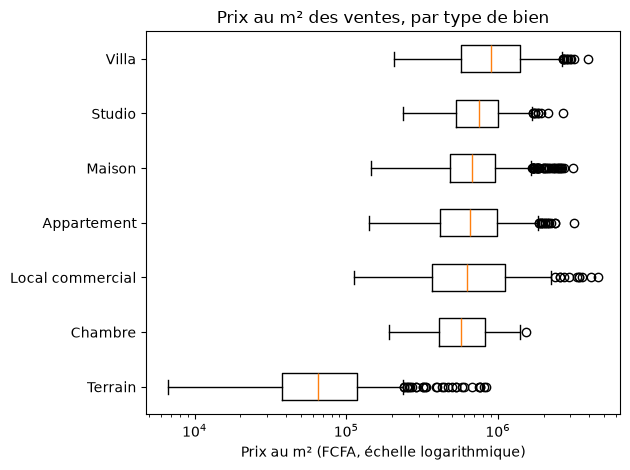

In [8]:
ventes = propres[propres["transaction"] == "vente"].copy()
ventes["prix_m2"] = ventes["prix_fcfa"] / ventes["surface_m2"]
print(ventes["prix_m2"].describe().round(0))

types = ventes.groupby("type_bien")["prix_m2"].median().sort_values().index
donnees_boite = [ventes.loc[ventes["type_bien"] == t, "prix_m2"] for t in types]
plt.boxplot(donnees_boite, tick_labels=types, vert=False)
plt.xscale("log")
plt.xlabel("Prix au m² (FCFA, échelle logarithmique)")
plt.title("Prix au m² des ventes, par type de bien")
plt.tight_layout()
plt.show()

## 7. Villes les plus chères (au moins 10 ventes)

In [9]:
(ventes.groupby("ville")["prix_m2"]
 .agg(nombre="count", mediane="median")
 .query("nombre >= 10")
 .sort_values("mediane", ascending=False)
 .head(10).round(0))

,nombre,mediane
ville,,
Dakar,44,1021546.0
Rufisque,54,807320.0
Pikine,42,780855.0
Saint-Louis,55,723157.0
Ourossogui,69,707205.0
Touba,45,706127.0
Kolda,55,704725.0
Birkelane,46,697893.0
Vélingara,62,696853.0


## 8. Les locations, séparément

In [10]:
loyers = propres[(propres["transaction"] == "location") & (propres["periodicite"] == "mensuel")]
print(len(loyers), "locations avec périodicité mensuelle connue")
loyers["prix_fcfa"].describe().round(0)

171 locations avec périodicité mensuelle connue


count        171.0
mean      395292.0
std       293078.0
min        40000.0
25%       187500.0
50%       315000.0
75%       542500.0
max      1480000.0
Name: prix_fcfa, dtype: float64

## 9. NumPy : statistiques sur le prix au m²

NumPy travaille sur des **tableaux numériques** : une opération s'applique
à toutes les valeurs d'un coup (vectorisation), sans boucle.

In [11]:
prix_m2 = ventes["prix_m2"].to_numpy(dtype=float)     # tableau NumPy
print("nombre de ventes :", prix_m2.size)
print("moyenne          :", np.mean(prix_m2).round(0))
print("médiane          :", np.median(prix_m2).round(0))
print("écart-type       :", np.std(prix_m2).round(0))
print("minimum / maximum:", prix_m2.min().round(0), "/", prix_m2.max().round(0))

q1, q3 = np.percentile(prix_m2, [25, 75])
print("quartiles        :", round(q1), "et", round(q3))

nombre de ventes : 2534
moyenne          : 735795.0
médiane          : 624852.0
écart-type       : 561560.0
minimum / maximum: 6648.0 / 4603188.0
quartiles        : 353490 et 979080


La moyenne est supérieure à la médiane : quelques valeurs très élevées
« tirent » la moyenne vers le haut. La médiane résiste mieux aux valeurs extrêmes.

In [12]:
# Deux façons de repérer les valeurs extrêmes
z = (prix_m2 - prix_m2.mean()) / prix_m2.std()
print("écarts > 3 écarts-types (score z) :", int((np.abs(z) > 3).sum()))

seuil_haut = q3 + 1.5 * (q3 - q1)                   # règle des quartiles (IQR)
masque = prix_m2 > seuil_haut                       # tableau de True / False
print("au-dessus du seuil IQR            :", int(masque.sum()), "sur", prix_m2.size)
print("part des ventes concernées        :", round(masque.mean() * 100, 1), "%")

écarts > 3 écarts-types (score z) : 40
au-dessus du seuil IQR            : 105 sur 2534
part des ventes concernées        : 4.1 %


In [13]:
# Médiane et dispersion par type de bien, avec un masque NumPy
types_tableau = ventes["type_bien"].to_numpy()
for type_bien in np.unique(types_tableau):
    valeurs = prix_m2[types_tableau == type_bien]
    print(f"{type_bien:18s} n={valeurs.size:4d}  médiane={np.median(valeurs):10,.0f}  écart-type={np.std(valeurs):10,.0f}")

Appartement        n= 590  médiane=   656,661  écart-type=   446,690
Chambre            n= 157  médiane=   571,792  écart-type=   300,627
Local commercial   n= 144  médiane=   625,691  écart-type=   851,009
Maison             n= 536  médiane=   670,301  écart-type=   482,576
Studio             n= 302  médiane=   748,131  écart-type=   387,679
Terrain            n= 357  médiane=    64,765  écart-type=   126,807
Villa              n= 448  médiane=   906,133  écart-type=   645,488


In [14]:
# Histogramme du logarithme du prix au m² (les valeurs s'étalent sur plusieurs ordres de grandeur)
effectifs, bornes = np.histogram(np.log10(prix_m2), bins=8)
for effectif, debut, fin in zip(effectifs, bornes[:-1], bornes[1:]):
    print(f"de {10**debut:>10,.0f} à {10**fin:>10,.0f} FCFA/m² : {effectif} ventes")

de      6,648 à     15,057 FCFA/m² : 19 ventes
de     15,057 à     34,102 FCFA/m² : 63 ventes
de     34,102 à     77,237 FCFA/m² : 125 ventes
de     77,237 à    174,933 FCFA/m² : 121 ventes
de    174,933 à    396,204 FCFA/m² : 405 ventes
de    396,204 à    897,357 FCFA/m² : 1065 ventes
de    897,357 à  2,032,413 FCFA/m² : 651 ventes
de  2,032,413 à  4,603,188 FCFA/m² : 85 ventes


## Conclusions

- **Qualité** : particuliers est la source la plus dégradée (18,6 % de quarantaine), surtout à cause des valeurs manquantes : surface absente (73 lignes) et prix absent (57 lignes).
- **Quarantaine** : le motif principal est le prix absent ou illisible (98 lignes), devant la surface (88). Viennent ensuite les 61 lignes de l’agence dont le statut Disponible ne dit pas s’il s’agit d’une vente ou d’une location.
- **Prix** : le prix au m² varie beaucoup selon le type (terrain environ 65 000, villa environ 906 000) et on observe de nombreuses valeurs extrêmes. Elles sont gardées et signalées, car atypique ne veut pas dire faux.
- **Limites** : données synthétiques, prix demandés et non conclus, 219 locations sans périodicité, doublons probables signalés sans fusion.